**CH.SC.U4CSE24142 - SANTHOSH A - Customer Churn Classification**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay, classification_report
)

RANDOM_STATE = 42
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

In [ ]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: count, dtype: float64


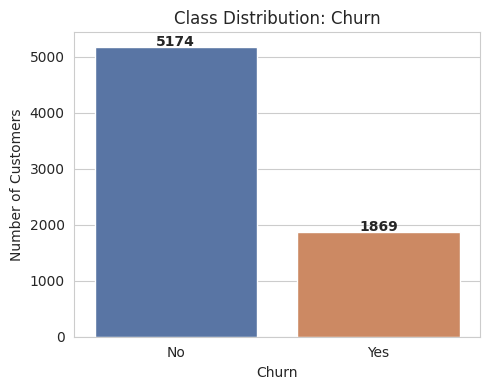

In [ ]:
churn_counts = df['Churn'].value_counts()
print(churn_counts)
print((churn_counts / churn_counts.sum() * 100).round(2))

plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df, order=['No', 'Yes'], palette=['#4C72B0', '#DD8452'])
plt.title('Class Distribution: Churn')
plt.ylabel('Number of Customers')
for i, v in enumerate(churn_counts.reindex(['No', 'Yes'])):
    plt.text(i, v + 20, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Remove Customer ID
data = df.drop(columns=['customerID']).copy()

# Convert TotalCharges to numeric (it's stored as string with some blank entries)
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
print("Missing values after numeric conversion:")
print(data.isnull().sum()[data.isnull().sum() > 0])

# Target encoding: Yes -> 1, No -> 0
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

# Separate X and y
X = data.drop(columns=['Churn'])
y = data['Churn']

# SeniorCitizen is numeric (0/1) but semantically categorical -> treat as categorical
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_cols = [c for c in numeric_cols if c != 'SeniorCitizen']
categorical_cols = categorical_cols + ['SeniorCitizen']

print("\nNumeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Missing values after numeric conversion:
TotalCharges    11
dtype: int64

Numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']


In [ ]:
# Train/Test split: 80/20, stratified on y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train churn rate: %.3f | Test churn rate: %.3f" % (y_train.mean(), y_test.mean()))

Train shape: (5634, 19)  Test shape: (1409, 19)
Train churn rate: 0.265 | Test churn rate: 0.265


In [ ]:
# ColumnTransformer: Imputer -> OneHotEncoder for categorical, Imputer -> Scaler for numeric
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# 5-fold Stratified CV used inside every GridSearchCV below
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


In [ ]:
results = {}  # model_name -> dict(best_estimator, best_params, cv_results, default_f1, y_pred, y_proba)

def run_model(name, base_estimator, param_grid, X_train, y_train, X_test, y_test,
              preprocessor, cv, needs_proba='predict_proba'):
    """Fits a default pipeline (for baseline F1) then GridSearchCV-tunes it (scoring=F1)."""

    # --- Default (untuned) model, for the hyperparameter-improvement comparison ---
    default_pipe = Pipeline(steps=[('prep', preprocessor), ('clf', base_estimator)])
    default_pipe.fit(X_train, y_train)
    default_pred = default_pipe.predict(X_test)
    default_f1 = f1_score(y_test, default_pred)

    # --- Grid search (tuned) ---
    pipe = Pipeline(steps=[('prep', preprocessor), ('clf', base_estimator)])
    grid = GridSearchCV(pipe, param_grid=param_grid, scoring='f1', cv=cv,
                         n_jobs=-1, refit=True)
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    if hasattr(best_model, 'predict_proba'):
        y_proba = best_model.predict_proba(X_test)[:, 1]
    elif hasattr(best_model, 'decision_function'):
        y_proba = best_model.decision_function(X_test)
    else:
        y_proba = y_pred

    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    }

    results[name] = {
        'best_estimator': best_model,
        'best_params': grid.best_params_,
        'cv_results': grid.cv_results_,
        'default_f1': default_f1,
        'tuned_f1': metrics['F1'],
        'y_pred': y_pred,
        'y_proba': y_proba,
        'metrics': metrics,
        'grid': grid,
    }

    print(f"=== {name} ===")
    print("Best params:", grid.best_params_)
    print("Default F1: %.4f | Tuned F1: %.4f" % (default_f1, metrics['F1']))
    print({k: round(v, 4) for k, v in metrics.items()})
    print()
    return results[name]

In [ ]:
knn_grid = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15],
    'clf__weights': ['uniform', 'distance'],
    'clf__p': [1, 2],   # p=1 -> manhattan, p=2 -> euclidean (covers the 'metric' dimension too)
}

_ = run_model('KNN', KNeighborsClassifier(), knn_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

=== KNN ===
Best params: {'clf__n_neighbors': 15, 'clf__p': 2, 'clf__weights': 'uniform'}
Default F1: 0.5476 | Tuned F1: 0.5766
{'Accuracy': 0.7821, 'Precision': 0.5954, 'Recall': 0.5588, 'F1': 0.5766, 'ROC-AUC': np.float64(0.8227)}



In [ ]:
dt_grid = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__max_depth': [3, 5, 7, 10, 15, None],
    'clf__min_samples_split': [2, 5, 10, 20],
    'clf__min_samples_leaf': [1, 2, 5, 10],
    'clf__max_features': ['sqrt', 'log2', None],
}
# Full grid = 3*6*4*4*3 = 864 combos * 5 folds = 4320 fits -> use RandomizedSearch-style
# reduction is avoided per spec; GridSearchCV with n_jobs=-1 handles this in reasonable time
# on this dataset size (~5600 train rows). If runtime is a concern, reduce lists above.

_ = run_model('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)


=== Decision Tree ===
Best params: {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__max_features': None, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2}
Default F1: 0.4934 | Tuned F1: 0.5989
{'Accuracy': 0.7984, 'Precision': 0.6347, 'Recall': 0.5668, 'F1': 0.5989, 'ROC-AUC': np.float64(0.8327)}



In [ ]:
nb_grid = {
    'clf__var_smoothing': [1e-11, 1e-10, 1e-9, 1e-8, 1e-7],
}

_ = run_model('Naive Bayes', GaussianNB(), nb_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

=== Naive Bayes ===
Best params: {'clf__var_smoothing': 1e-11}
Default F1: 0.5941 | Tuned F1: 0.5941
{'Accuracy': 0.6955, 'Precision': 0.4597, 'Recall': 0.8396, 'F1': 0.5941, 'ROC-AUC': np.float64(0.8075)}



In [ ]:
svm_grid = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__kernel': ['linear', 'rbf', 'poly'],
    'clf__gamma': ['scale', 0.01, 0.1, 1],
}

_ = run_model('SVM', SVC(probability=True, random_state=RANDOM_STATE), svm_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

In [ ]:
rf_grid = {
    'clf__n_estimators': [100, 200, 300, 500],
    'clf__max_depth': [5, 10, 15, 20, None],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 5],
    'clf__max_features': ['sqrt', 'log2'],
}

_ = run_model('Random Forest', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

=== Random Forest ===
Best params: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Default F1: 0.5495 | Tuned F1: 0.5848
{'Accuracy': 0.8055, 'Precision': 0.6748, 'Recall': 0.516, 'F1': 0.5848, 'ROC-AUC': np.float64(0.8424)}



In [ ]:
bagging_grid = {
    'clf__n_estimators': [10, 50, 100, 200],
    'clf__max_samples': [0.5, 0.7, 1.0],
    'clf__max_features': [0.5, 0.7, 1.0],
    'clf__bootstrap': [True, False],
}

bagging_base = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    random_state=RANDOM_STATE
)

_ = run_model('Bagging', bagging_base, bagging_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

=== Bagging ===
Best params: {'clf__bootstrap': True, 'clf__max_features': 0.7, 'clf__max_samples': 0.7, 'clf__n_estimators': 200}
Default F1: 0.5331 | Tuned F1: 0.5714
{'Accuracy': 0.7935, 'Precision': 0.6361, 'Recall': 0.5187, 'F1': 0.5714, 'ROC-AUC': np.float64(0.8253)}



In [ ]:
ada_grid = {
    'clf__n_estimators': [50, 100, 200, 300],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
}

_ = run_model('AdaBoost', AdaBoostClassifier(random_state=RANDOM_STATE), ada_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

=== AdaBoost ===
Best params: {'clf__learning_rate': 0.5, 'clf__n_estimators': 300}
Default F1: 0.5939 | Tuned F1: 0.5920
{'Accuracy': 0.8034, 'Precision': 0.659, 'Recall': 0.5374, 'F1': 0.592, 'ROC-AUC': np.float64(0.8425)}



In [ ]:
gb_grid = {
    'clf__n_estimators': [50, 100, 200],
    'clf__learning_rate': [0.01, 0.05, 0.1],
    'clf__max_depth': [2, 3, 5],
    'clf__subsample': [0.7, 0.9, 1.0],
}

_ = run_model('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE), gb_grid,
              X_train, y_train, X_test, y_test, preprocessor, cv)

=== Gradient Boosting ===
Best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 100, 'clf__subsample': 0.9}
Default F1: 0.5916 | Tuned F1: 0.5854
{'Accuracy': 0.807, 'Precision': 0.6809, 'Recall': 0.5134, 'F1': 0.5854, 'ROC-AUC': np.float64(0.8462)}



In [ ]:
rows = []
for name, r in results.items():
    row = {'Model': name, 'Best Parameters': r['best_params']}
    row.update({k: round(v, 4) for k, v in r['metrics'].items()})
    rows.append(row)

results_df = pd.DataFrame(rows).set_index('Model')
results_df = results_df[['Best Parameters', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']]
results_df.sort_values('F1', ascending=False)

,Best Parameters,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Decision Tree,"{'clf__criterion': 'entropy', 'clf__max_depth'...",0.7984,0.6347,0.5668,0.5989,0.8327
Naive Bayes,{'clf__var_smoothing': 1e-11},0.6955,0.4597,0.8396,0.5941,0.8075
AdaBoost,"{'clf__learning_rate': 0.5, 'clf__n_estimators...",0.8034,0.6590,0.5374,0.5920,0.8425
Gradient Boosting,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.8070,0.6809,0.5134,0.5854,0.8462
Random Forest,"{'clf__max_depth': 10, 'clf__max_features': 's...",0.8055,0.6748,0.5160,0.5848,0.8424
KNN,"{'clf__n_neighbors': 15, 'clf__p': 2, 'clf__we...",0.7821,0.5954,0.5588,0.5766,0.8227
Bagging,"{'clf__bootstrap': True, 'clf__max_features': ...",0.7935,0.6361,0.5187,0.5714,0.8253


In [ ]:
hp_rows = []
for name, r in results.items():
    default_f1 = r['default_f1']
    tuned_f1 = r['tuned_f1']
    hp_rows.append({
        'Model': name,
        'Default F1': round(default_f1, 4),
        'Tuned F1': round(tuned_f1, 4),
        'Improvement': round(tuned_f1 - default_f1, 4),
        'Improvement %': round(100 * (tuned_f1 - default_f1) / max(default_f1, 1e-9), 2)
    })

hp_df = pd.DataFrame(hp_rows).set_index('Model').sort_values('Improvement', ascending=False)
hp_df

,Default F1,Tuned F1,Improvement,Improvement %
Model,,,,
Decision Tree,0.4934,0.5989,0.1054,21.37
Bagging,0.5331,0.5714,0.0383,7.18
Random Forest,0.5495,0.5848,0.0353,6.42
KNN,0.5476,0.5766,0.0289,5.28
Naive Bayes,0.5941,0.5941,0.0000,0.00
AdaBoost,0.5939,0.5920,-0.0018,-0.31
Gradient Boosting,0.5916,0.5854,-0.0062,-1.05


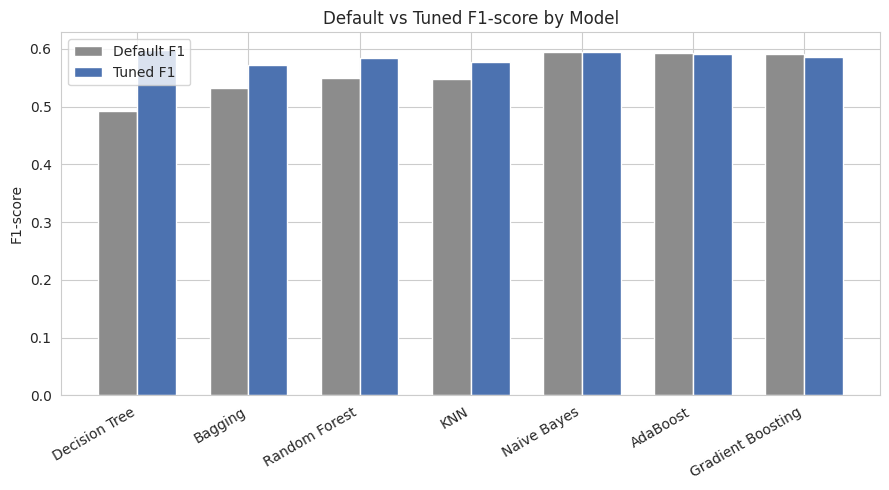

In [ ]:
plt.figure(figsize=(9,5))
x = np.arange(len(hp_df))
width = 0.35
plt.bar(x - width/2, hp_df['Default F1'], width, label='Default F1', color='#8C8C8C')
plt.bar(x + width/2, hp_df['Tuned F1'], width, label='Tuned F1', color='#4C72B0')
plt.xticks(x, hp_df.index, rotation=30, ha='right')
plt.ylabel('F1-score')
plt.title('Default vs Tuned F1-score by Model')
plt.legend()
plt.tight_layout()
plt.show()

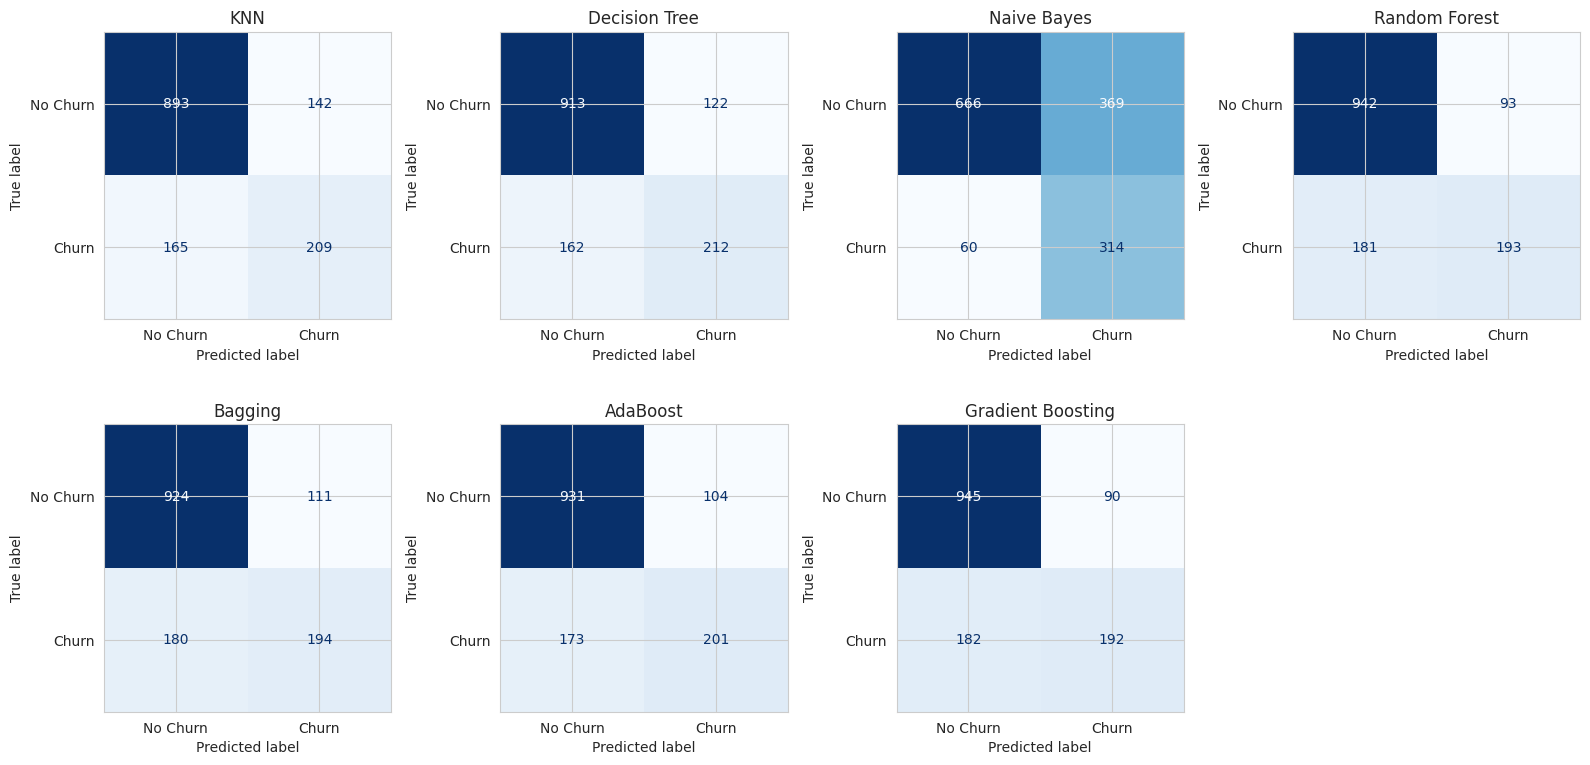

In [ ]:
n_models = len(results)
n_cols = 4
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
axes = axes.flatten()

for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['y_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

for ax in axes[len(results):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

Best model by F1: Decision Tree
TN=913  FP=122  FN=162  TP=212
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.87      1035
       Churn       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



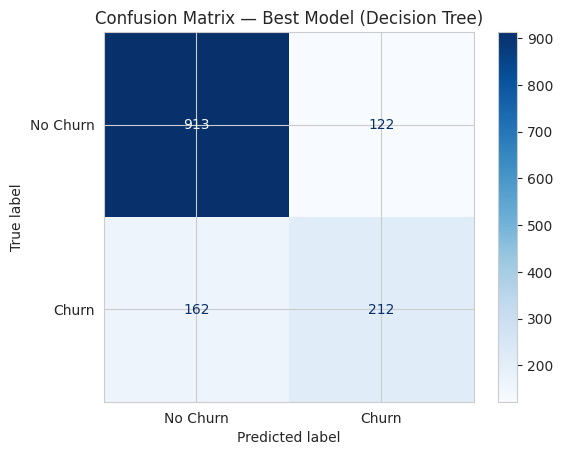

In [ ]:
# Best model by F1 - highlighted confusion matrix
best_model_name = results_df['F1'].astype(float).idxmax()
best_r = results[best_model_name]
cm = confusion_matrix(y_test, best_r['y_pred'])
tn, fp, fn, tp = cm.ravel()

print(f"Best model by F1: {best_model_name}")
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(classification_report(y_test, best_r['y_pred'], target_names=['No Churn', 'Churn']))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn']).plot(cmap='Blues')
plt.title(f'Confusion Matrix — Best Model ({best_model_name})')
plt.show()

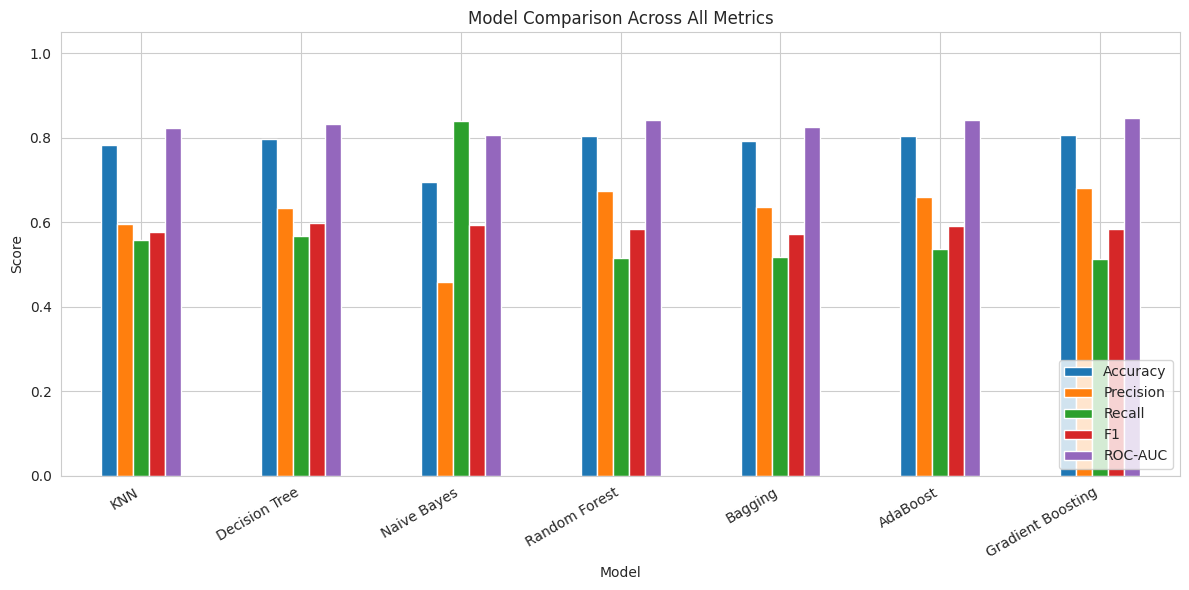

In [ ]:
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
plot_df = results_df[metric_cols].astype(float)

plot_df.plot(kind='bar', figsize=(12,6))
plt.title('Model Comparison Across All Metrics')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

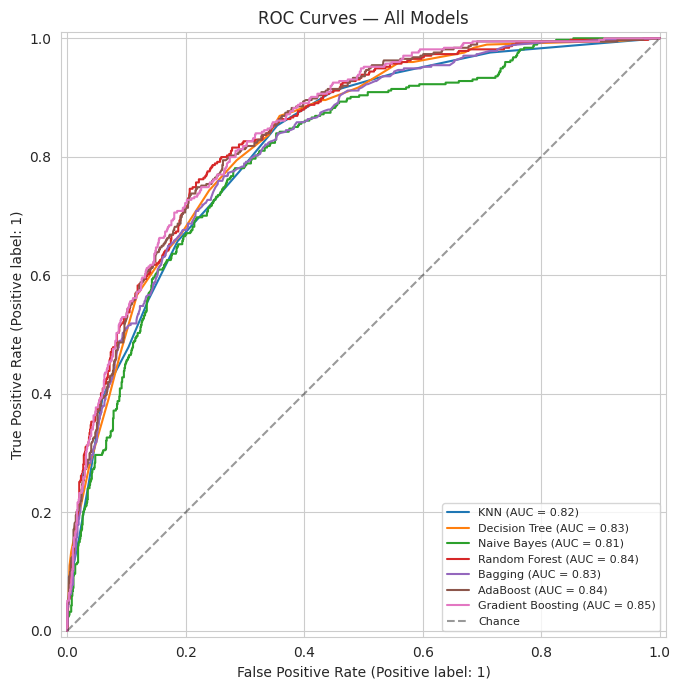

In [ ]:
plt.figure(figsize=(8,7))
ax = plt.gca()
for name, r in results.items():
    RocCurveDisplay.from_predictions(y_test, r['y_proba'], name=name, ax=ax)
plt.plot([0,1],[0,1], 'k--', alpha=0.4, label='Chance')
plt.title('ROC Curves — All Models')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

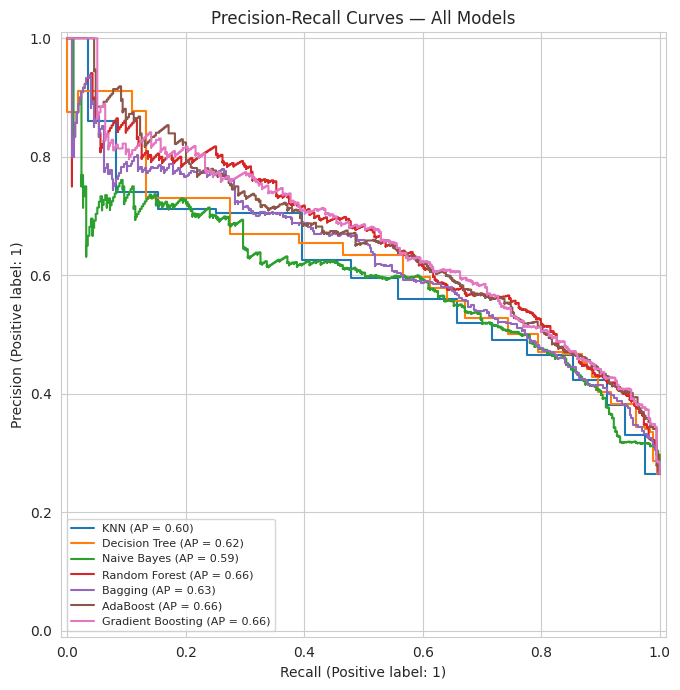

In [ ]:
plt.figure(figsize=(8,7))
ax = plt.gca()
for name, r in results.items():
    PrecisionRecallDisplay.from_predictions(y_test, r['y_proba'], name=name, ax=ax)
plt.title('Precision-Recall Curves — All Models')
plt.legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

param_clf__n_neighbors
3     0.510668
5     0.538010
7     0.549257
9     0.550018
11    0.558982
15    0.570791
Name: mean_test_score, dtype: float64


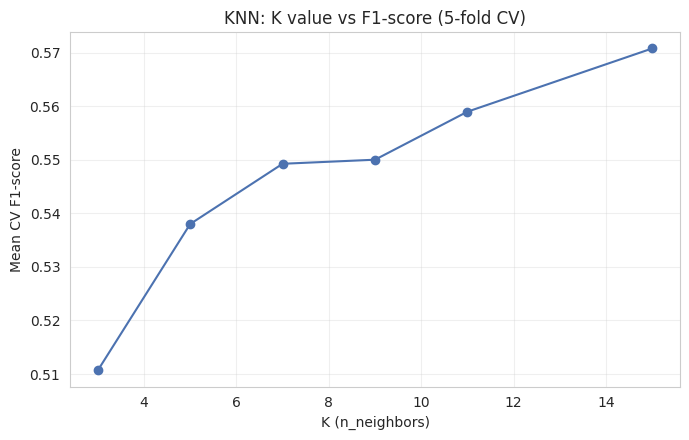

In [ ]:
knn_cv = pd.DataFrame(results['KNN']['cv_results'])
k_f1 = knn_cv.groupby('param_clf__n_neighbors')['mean_test_score'].mean().sort_index()
print(k_f1)

plt.figure(figsize=(7,4.5))
plt.plot(k_f1.index, k_f1.values, marker='o', color='#4C72B0')
plt.xlabel('K (n_neighbors)')
plt.ylabel('Mean CV F1-score')
plt.title('KNN: K value vs F1-score (5-fold CV)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

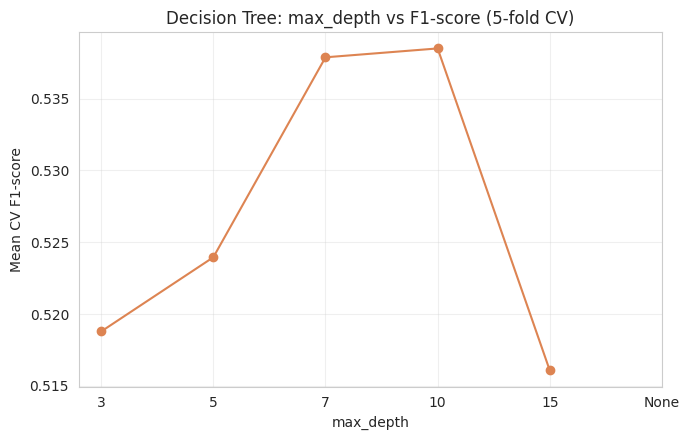

In [ ]:
# Decision Tree: max_depth vs F1 (same idea, section 12.6 / inference Q2-Q3)
dt_cv = pd.DataFrame(results['Decision Tree']['cv_results'])
depth_f1 = dt_cv.groupby('param_clf__max_depth')['mean_test_score'].mean()
depth_f1.index = depth_f1.index.astype(str)
depth_f1 = depth_f1.reindex(['3','5','7','10','15','None'])

plt.figure(figsize=(7,4.5))
plt.plot(range(len(depth_f1)), depth_f1.values, marker='o', color='#DD8452')
plt.xticks(range(len(depth_f1)), depth_f1.index)
plt.xlabel('max_depth')
plt.ylabel('Mean CV F1-score')
plt.title('Decision Tree: max_depth vs F1-score (5-fold CV)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

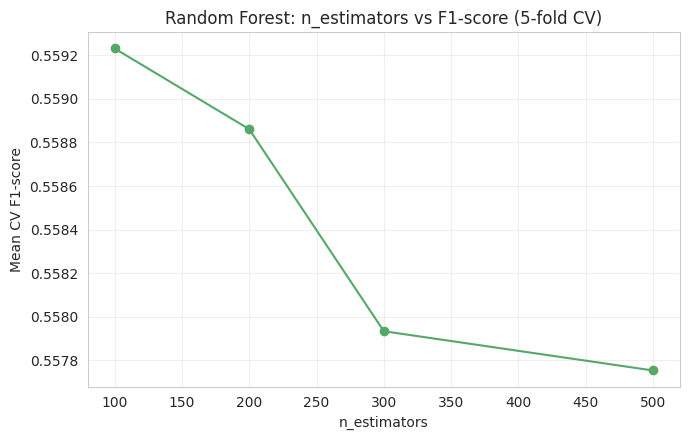

In [ ]:
# Random Forest: n_estimators vs F1 (inference Q4)
rf_cv = pd.DataFrame(results['Random Forest']['cv_results'])
n_est_f1 = rf_cv.groupby('param_clf__n_estimators')['mean_test_score'].mean().sort_index()

plt.figure(figsize=(7,4.5))
plt.plot(n_est_f1.index, n_est_f1.values, marker='o', color='#55A868')
plt.xlabel('n_estimators')
plt.ylabel('Mean CV F1-score')
plt.title('Random Forest: n_estimators vs F1-score (5-fold CV)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

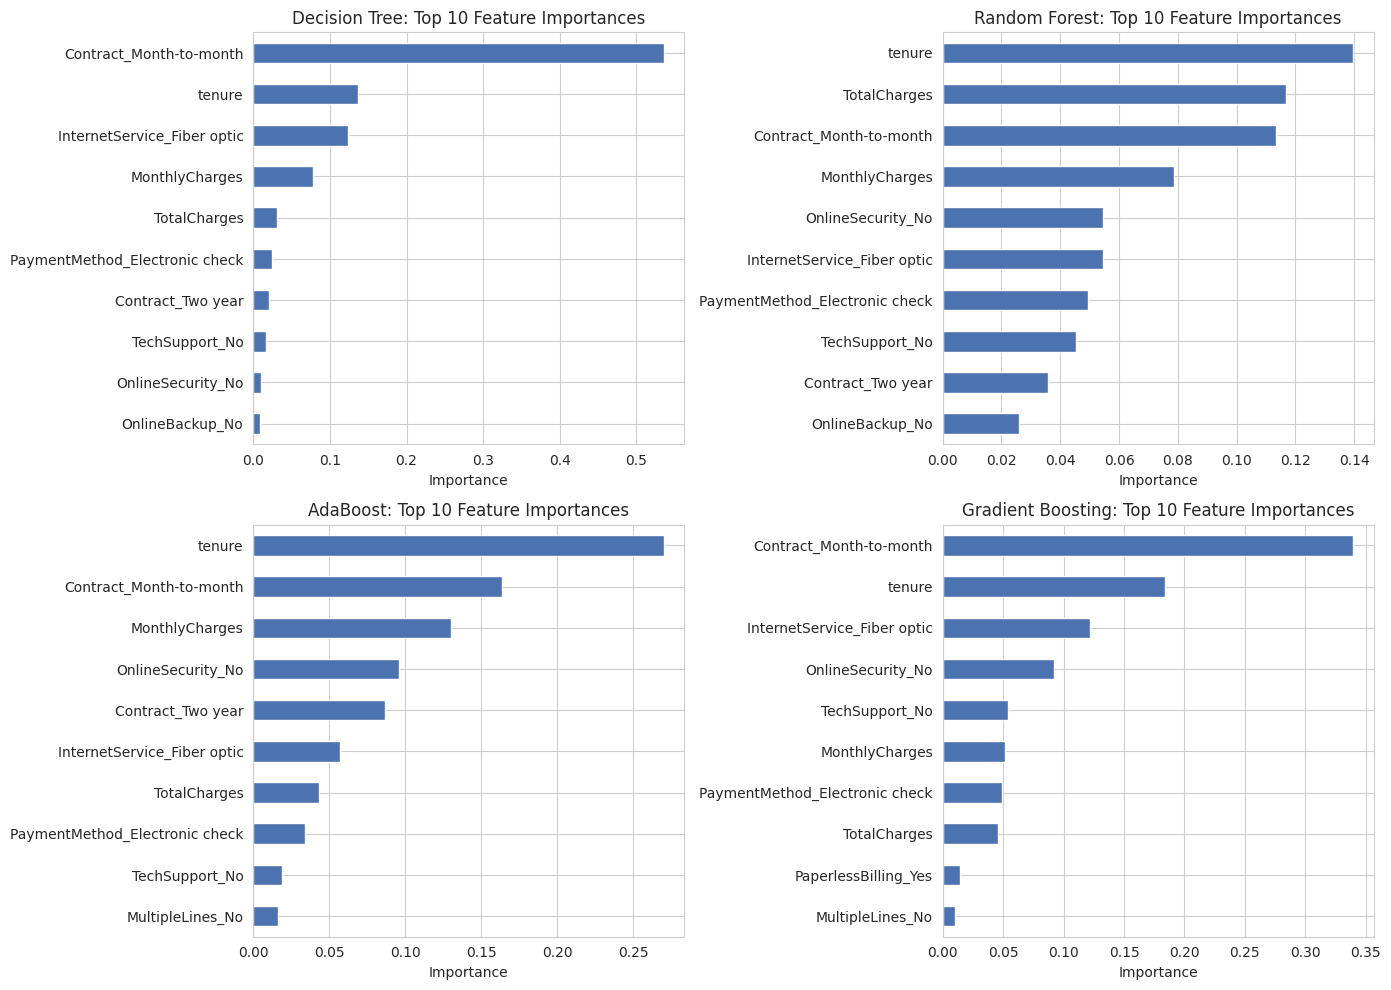

In [ ]:
def get_feature_names(preprocessor):
    num_features = numeric_cols
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
    cat_features = list(cat_encoder.get_feature_names_out(categorical_cols))
    return num_features + cat_features

importance_models = ['Decision Tree', 'Random Forest', 'AdaBoost', 'Gradient Boosting']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, name in zip(axes, importance_models):
    est = results[name]['best_estimator']
    clf = est.named_steps['clf']
    prep = est.named_steps['prep']
    feat_names = get_feature_names(prep)

    if hasattr(clf, 'feature_importances_'):
        importances = clf.feature_importances_
    else:
        importances = np.zeros(len(feat_names))

    imp_series = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(10)
    imp_series.sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
    ax.set_title(f'{name}: Top 10 Feature Importances')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.show()